## Dataset Overview: Car Price Prediction
**MCC Machine Learning Track — Week 3: Regression Task**

This dataset contains **1,000 records** of vehicles designed for regression modeling. The goal is to predict a car's **`Price`** based on its specifications, age, usage, and configuration.

### Features Description
| Feature | Data Type | Role | Description |
| :--- | :--- | :--- | :--- |
| **`Make`** | Categorical | Feature | Manufacturer brand of the car (`Honda`, `Ford`, `BMW`, `Audi`, `Toyota`) |
| **`Model`** | Categorical | Feature | Specific model designation (`Model A`, `Model B`, `Model C`, `Model D`, `Model E`) |
| **`Year`** | Numerical | Feature | Manufacturing year of the vehicle |
| **`Engine Size`** | Numerical | Feature | Engine displacement volume (in liters) |
| **`Mileage`** | Numerical | Feature | Total distance driven by the vehicle |
| **`Fuel Type`** | Categorical | Feature | Type of fuel used (`Petrol`, `Diesel`, `Electric`) |
| **`Transmission`** | Categorical | Feature | Gearbox type (`Manual`, `Automatic`) |
| **`Price`** | Numerical | **Target ($y$)** | Market price of the car |

# 1. Data Understanding

1. Import the necessary libraries for data analysis, visualization, preprocessing, and regression modeling.
2. Load the `Car_Price_Prediction.csv` dataset and preview a random sample of rows.
3. Inspect all column names and check the overall shape of the dataset.
4. Check the data types and general information of all columns.
5. Check for any missing (null) values in the dataset.
6. Check for any duplicate rows in the dataset.
7. Generate a statistical summary for the numerical features (`Year`, `Engine Size`, `Mileage`, `Price`).
8. Generate a statistical summary for the categorical features (`Make`, `Model`, `Fuel Type`, `Transmission`).
9. Explore the car categories: identify all unique car brands (`Make`), models (`Model`), fuel types (`Fuel Type`), and transmissions (`Transmission`), and check how many cars belong to each category.

In [60]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import SGDRegressor




In [ ]:

folder_path = r"C:\Users\aisha\Desktop\mcc_kfs\task week 3"

os.listdir(folder_path)

['Car_Price_Prediction.csv', 'regression_task.ipynb']

In [11]:
df= pd.read_csv('Car_Price_Prediction.csv')
df.sample(5)
#df.head(5)

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
953,Toyota,Model C,2017,4.0,130400,Electric,Manual,28757.617129
103,Ford,Model D,2000,2.8,134670,Petrol,Manual,18367.763349
128,BMW,Model C,2017,4.3,184750,Electric,Manual,23591.142062
435,Audi,Model A,2007,3.0,123916,Petrol,Manual,22141.504546
672,Ford,Model C,2008,4.5,142813,Electric,Automatic,27243.212472


In [12]:
df.shape

(1000, 8)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Make          1000 non-null   str    
 1   Model         1000 non-null   str    
 2   Year          1000 non-null   int64  
 3   Engine Size   1000 non-null   float64
 4   Mileage       1000 non-null   int64  
 5   Fuel Type     1000 non-null   str    
 6   Transmission  1000 non-null   str    
 7   Price         1000 non-null   float64
dtypes: float64(2), int64(2), str(4)
memory usage: 62.6 KB


In [8]:
df.isnull().sum()

Make            0
Model           0
Year            0
Engine Size     0
Mileage         0
Fuel Type       0
Transmission    0
Price           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Year,Engine Size,Mileage,Price
count,1000.000000,1000.000000,1000.00000,1000.000000
mean,2010.688000,2.798300,97192.48700,25136.615530
std,6.288577,1.024137,59447.31576,5181.401368
min,2000.000000,1.000000,56.00000,6704.953524
25%,2005.000000,1.900000,44768.75000,21587.878370
50%,2011.000000,2.800000,94411.50000,25189.325247
75%,2016.000000,3.700000,148977.75000,28806.368974
max,2021.000000,4.500000,199867.00000,41780.504635


In [13]:
df.select_dtypes('str').describe()

,Make,Model,Fuel Type,Transmission
count,1000,1000,1000,1000
unique,5,5,3,2
top,Ford,Model B,Diesel,Manual
freq,225,212,344,511


In [14]:
categories=df.select_dtypes('str').columns
for cat in categories:
    display(df[cat].value_counts())

Make
Ford      225
Audi      212
Honda     198
Toyota    187
BMW       178
Name: count, dtype: int64

Model
Model B    212
Model C    205
Model A    202
Model D    197
Model E    184
Name: count, dtype: int64

Fuel Type
Diesel      344
Petrol      331
Electric    325
Name: count, dtype: int64

Transmission
Manual       511
Automatic    489
Name: count, dtype: int64

# 2. EDA and Feature Engineering

1. Search for any potential **outliers** across the numerical features (`Year`, `Engine Size`, `Mileage`, `Price`).
2. Investigate the **distribution** of each numerical feature.
3. Explore the relationship between each numerical feature and the target variable (**`Price`**).
4. Check the **frequency distribution** of each categorical feature (`Make`, `Model`, `Fuel Type`, `Transmission`) to see the count of cars in each category.
5. Investigate how the car **`Price`** varies across different car makes, models, fuel types, and transmission types.
6. Examine the **correlation** between all numerical features and **`Price`**.
7. **Feature Engineering:** Before preprocessing and splitting the data, explore whether you can create any useful new features from the existing columns (e.g., using `Year` or `Mileage`).

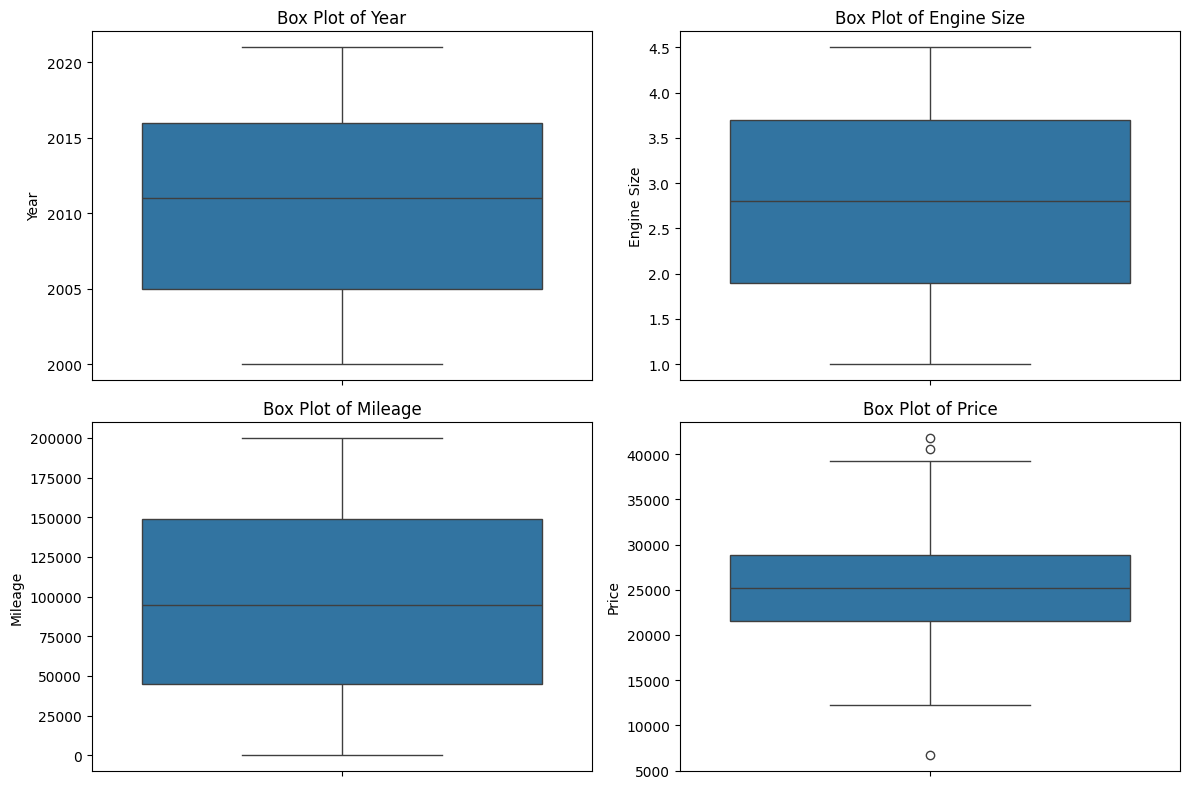

In [17]:
num_cols = ['Year', 'Engine Size', 'Mileage', 'Price']
plt.figure(figsize=(12, 8))
for i, col in enumerate(num_cols):
    plt.subplot(2, 2, i+1)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()


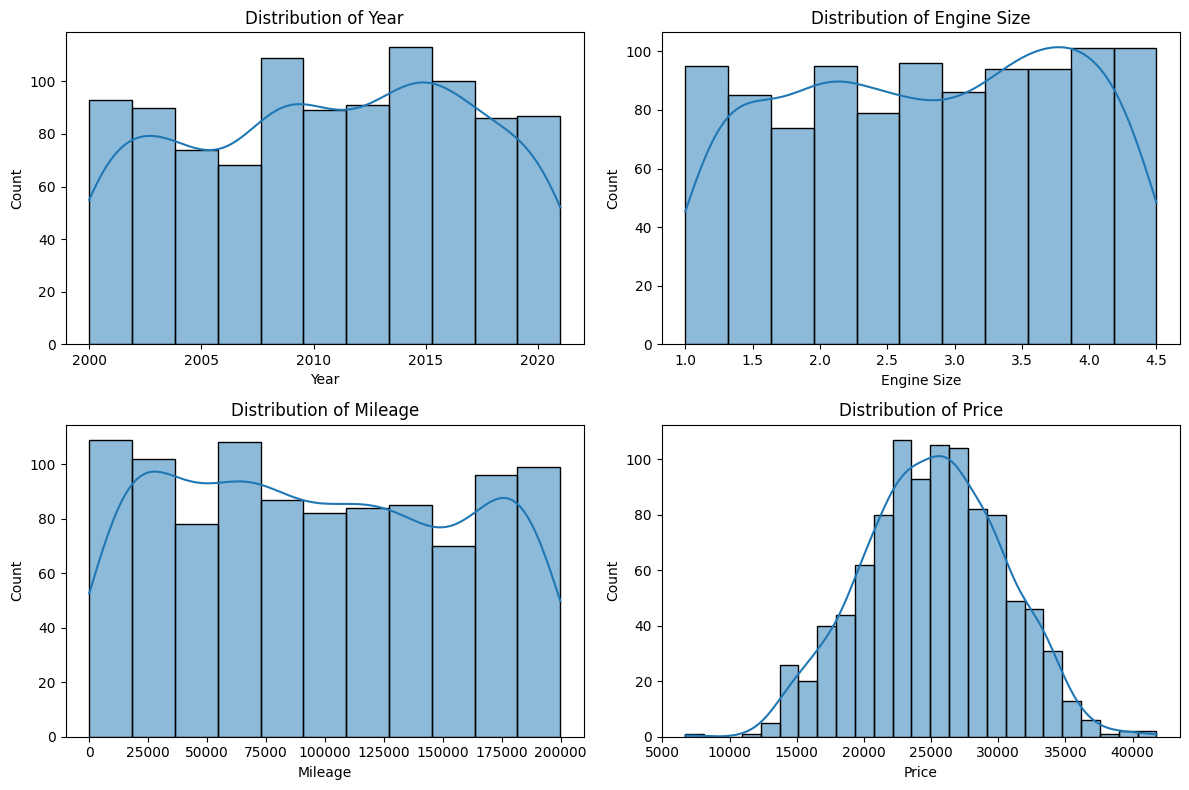

In [19]:
num_cols = ['Year', 'Engine Size', 'Mileage', 'Price']

plt.figure(figsize=(12, 8))

for i, col in enumerate(num_cols):
    plt.subplot(2, 2, i+1)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

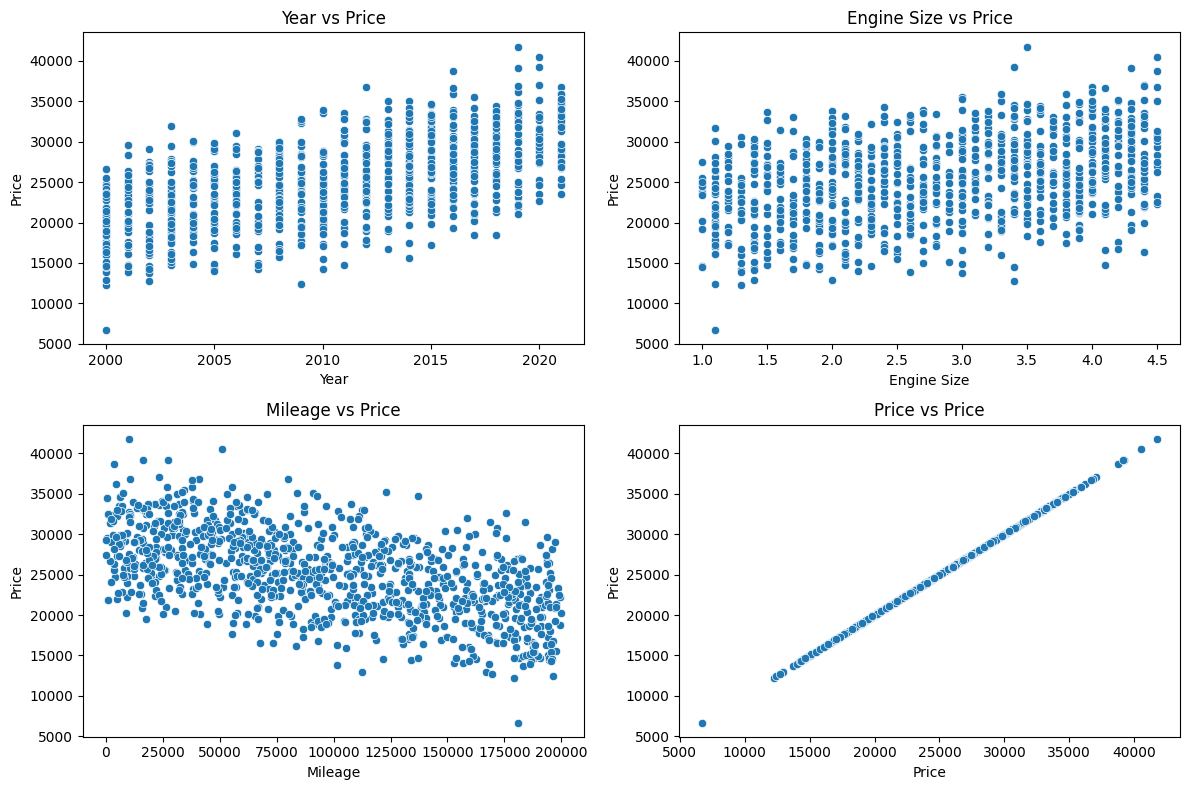

In [20]:
plt.figure(figsize=(12, 8))

for i, col in enumerate(num_cols):
    plt.subplot(2, 2, i+1)
    sns.scatterplot(data=df, x=col, y='Price')
    plt.title(f'{col} vs Price')

plt.tight_layout()
plt.show()

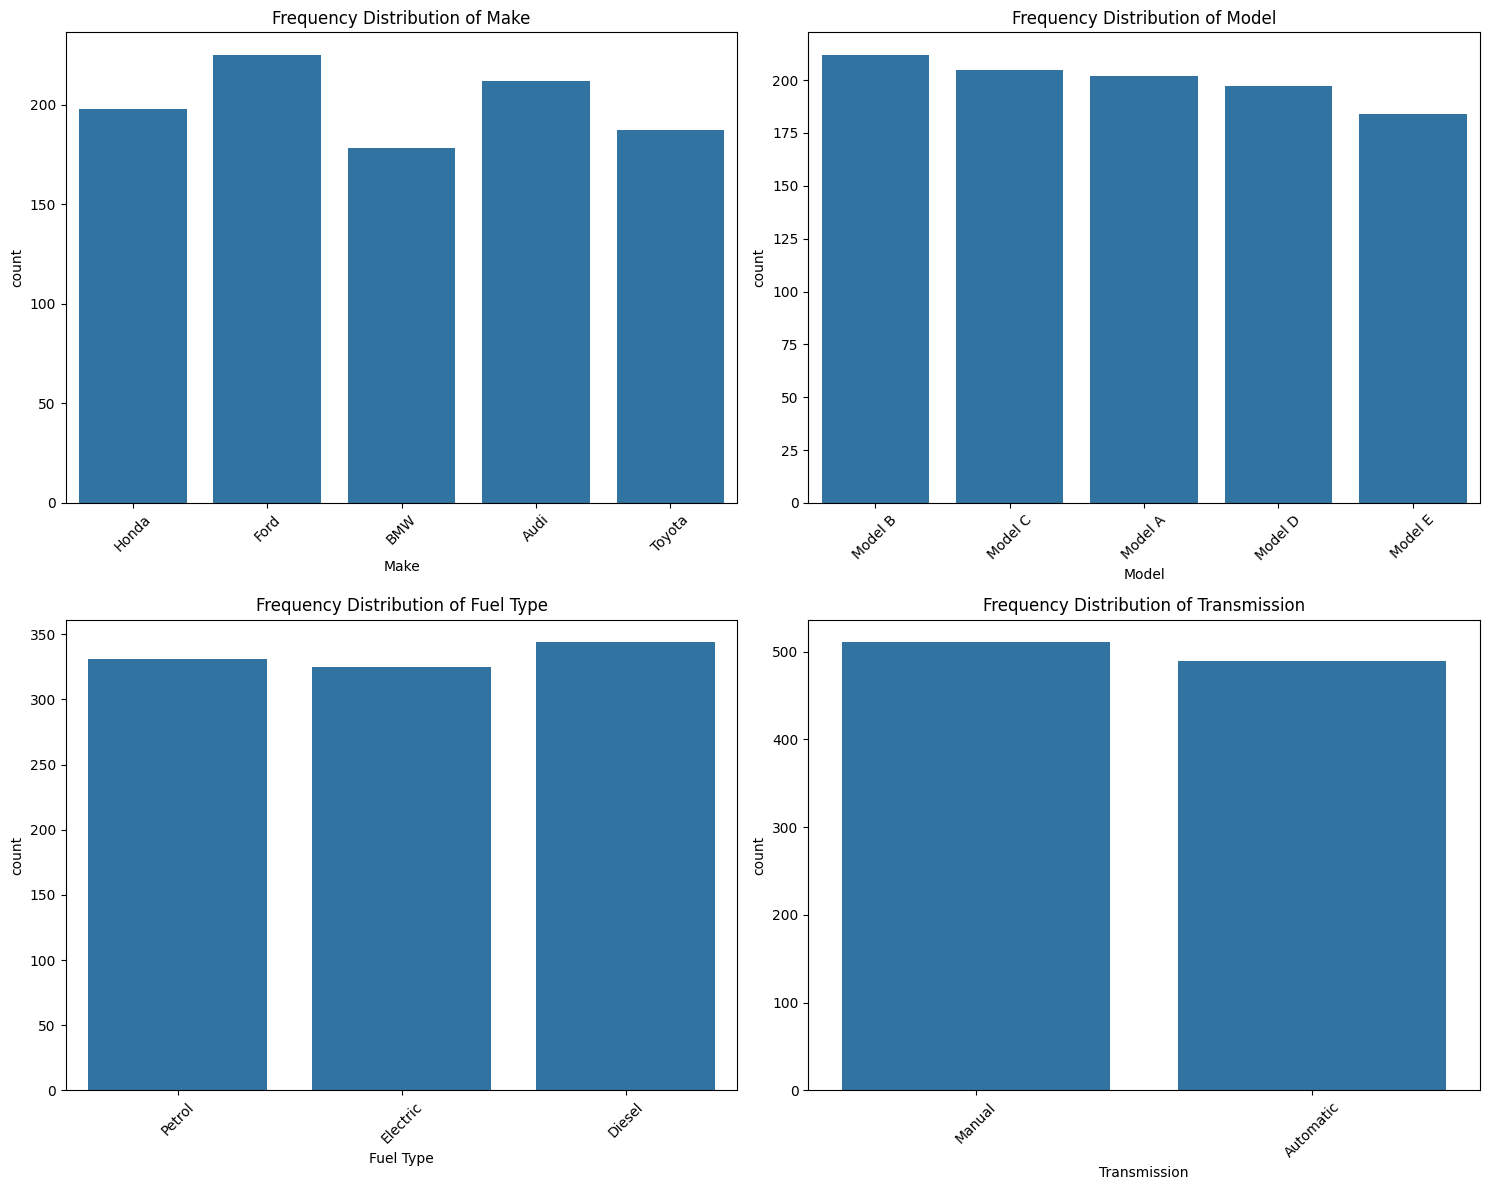

In [22]:
cat_cols = ['Make', 'Model', 'Fuel Type', 'Transmission']
plt.figure(figsize=(15, 12))

for i, col in enumerate(cat_cols):
    plt.subplot(2, 2, i+1)
    sns.countplot(data=df, x=col)
    plt.title(f'Frequency Distribution of {col}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

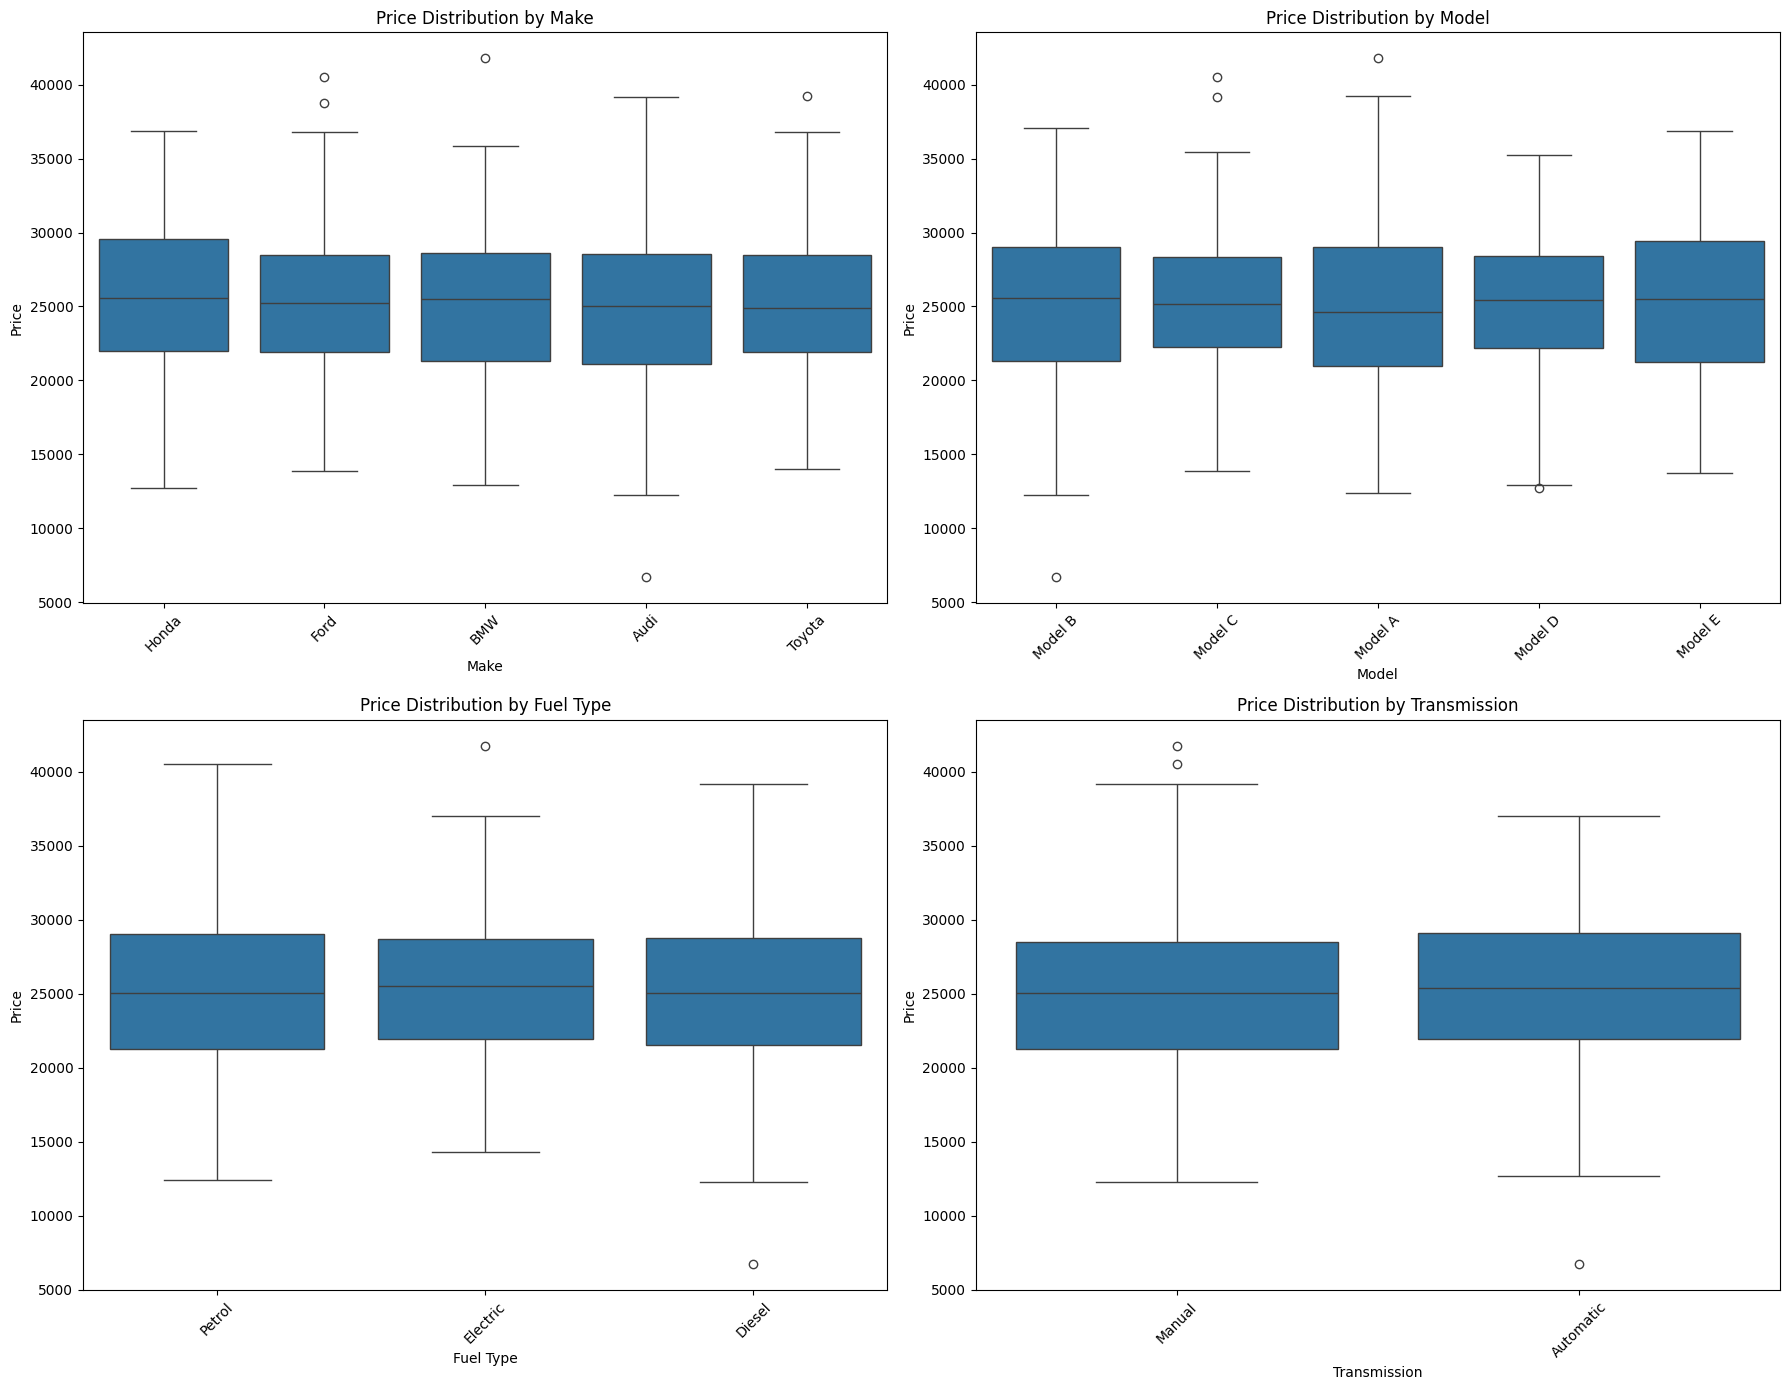

In [23]:
cat_cols = ['Make', 'Model', 'Fuel Type', 'Transmission']
plt.figure(figsize=(18, 14))

for i, col in enumerate(cat_cols):
    plt.subplot(2, 2, i+1)
    sns.boxplot(data=df, x=col, y='Price')
    plt.title(f'Price Distribution by {col}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Price          1.000000
Year           0.609631
Engine Size    0.383951
Mileage       -0.556560
Name: Price, dtype: float64


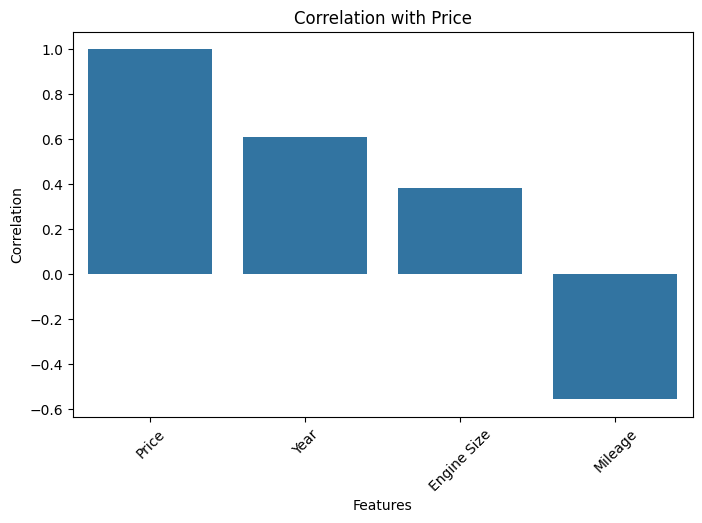

In [25]:
num_cols = df.select_dtypes(include='number').columns
correlations = df[num_cols].corr()['Price'].sort_values(ascending=False)

print(correlations)
plt.figure(figsize=(8, 5))

sns.barplot(x=correlations.index, y=correlations.values)

plt.title('Correlation with Price')
plt.xlabel('Features')
plt.ylabel('Correlation')
plt.xticks(rotation=45)

plt.show()

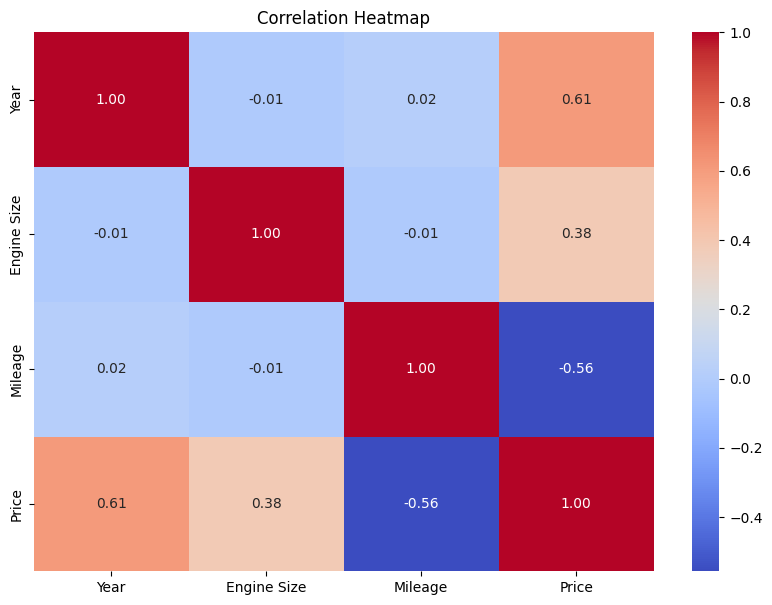

In [26]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [27]:
from datetime import datetime

current_year = datetime.now().year

df['Car Age'] = current_year - df['Year']

In [28]:
df['Mileage per Year'] = df['Mileage'] / df['Car Age']

In [29]:
df['Mileage Category'] = pd.cut(
    df['Mileage'],
    bins=[-1, 50000, 150000, float('inf')],
    labels=['Low', 'Medium', 'High']
)

In [30]:
df[['Year', 'Car Age', 'Mileage', 'Mileage per Year', 'Mileage Category']].head()

,Year,Car Age,Mileage,Mileage per Year,Mileage Category
0,2015,11,74176,6743.272727,Medium
1,2014,12,94799,7899.916667,Medium
2,2006,20,98385,4919.250000,Medium
3,2015,11,88919,8083.545455,Medium
4,2004,22,138482,6294.636364,Medium


# 3. Preprocessing

1. Separate the features ($X$) and the target variable ($y$ — `Price`), then split the dataset into training and testing sets.
2. Encode the categorical features (`Make`, `Model`, `Fuel Type`, `Transmission`) into numerical values.
3. Scale the numerical features.
4. Apply any additional preprocessing steps if needed.

> **Hints:**
> - In scaling, there is a scaler called **`StandardScaler`** that you can use if you have outliers in the data.
> - Take care and watch out for **Data Leakage**!

In [34]:
X = df.drop('Price', axis=1)
y = df['Price']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [36]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 10)
X_test: (200, 10)
y_train: (800,)
y_test: (200,)


In [46]:
cat_features = ['Make', 'Model', 'Fuel Type', 'Transmission']
encoder = OneHotEncoder(handle_unknown='ignore')
X_train_encoded = encoder.fit_transform(X_train[cat_features])

X_test_encoded = encoder.transform(X_test[cat_features])

In [49]:
num_features = X.select_dtypes(include='number').columns
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[num_features])

X_test_scaled = scaler.transform(X_test[num_features])

In [51]:

X_train_final = hstack([
    X_train_scaled,
    X_train_encoded
])

X_test_final = hstack([
    X_test_scaled,
    X_test_encoded
])

In [52]:
print("Training Features:", X_train_final.shape)
print("Testing Features:", X_test_final.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 20)
Testing Features: (200, 20)
Training Target: (800,)
Testing Target: (200,)


# 4. Modeling

1. Train a **Linear Regression** model on the training data.
2. Evaluate the **Linear Regression** model on the **training set** using **MSE**, **MAE**, and **$R^2$ Score**.
3. Evaluate the **Linear Regression** model on the **testing set** using **MSE**, **MAE**, and **$R^2$ Score**.
4. Train an **SGDRegressor** model on the training data.
5. Evaluate the **SGDRegressor** model on the **training set** using **MSE**, **MAE**, and **$R^2$ Score**.
6. Evaluate the **SGDRegressor** model on the **testing set** using **MSE**, **MAE**, and **$R^2$ Score**.

In [57]:
lr_model = LinearRegression()

lr_model.fit(X_train_final, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [58]:
y_train_pred = lr_model.predict(X_train_final)

In [59]:
print("Training Results")
print("MSE:", mean_squared_error(y_train, y_train_pred))
print("MAE:", mean_absolute_error(y_train, y_train_pred))
print("R2 Score:", r2_score(y_train, y_train_pred))

Training Results
MSE: 4105832.721264766
MAE: 1600.325807011342
R2 Score: 0.8461226489487221


In [61]:
y_test_pred = lr_model.predict(X_test_final)

print("Testing Results")
print("MSE:", mean_squared_error(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("R2 Score:", r2_score(y_test, y_test_pred))

Testing Results
MSE: 5023798.327632069
MAE: 1815.2191468244514
R2 Score: 0.8164264943799182


In [62]:
sgd_model = SGDRegressor(
    max_iter=1000,
    random_state=42
)

In [63]:
sgd_model.fit(X_train_final, y_train)

,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide `.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the prediction exactly right.For epsilon-insensitive, any differences between the current predictionand the correct label are ignored if they are less than this threshold.Values must be in the range `[0.0, inf)`.",0.1
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42


In [64]:
y_train_pred_sgd = sgd_model.predict(X_train_final)

print("SGD Training Results")
print("MSE:", mean_squared_error(y_train, y_train_pred_sgd))
print("MAE:", mean_absolute_error(y_train, y_train_pred_sgd))
print("R2 Score:", r2_score(y_train, y_train_pred_sgd))

SGD Training Results
MSE: 4107389.5345479823
MAE: 1599.991971967512
R2 Score: 0.8460643030977424


In [65]:
y_test_pred_sgd = sgd_model.predict(X_test_final)

print("SGD Testing Results")
print("MSE:", mean_squared_error(y_test, y_test_pred_sgd))
print("MAE:", mean_absolute_error(y_test, y_test_pred_sgd))
print("R2 Score:", r2_score(y_test, y_test_pred_sgd))

SGD Testing Results
MSE: 5022482.636800017
MAE: 1813.7159348728655
R2 Score: 0.816474570748156
